In [59]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from datetime import datetime
import joblib

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import KNNImputer

# regression model
from sklearn.linear_model import LinearRegression, Lasso,ElasticNet,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor,AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor 
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

# evaluation 
from sklearn import metrics
import eli5
from eli5.sklearn import PermutationImportance
from IPython.display import display

pd.set_option('display.float_format',  '{:.3f}'.format)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)

import warnings
warnings.filterwarnings("ignore")

In [60]:
df= pd.read_csv(r"D:\ML Projects\Melbourne_housing\Dataset\melb_data.csv",encoding='latin-1')
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.000,S,Biggin,3/12/2016,2.500,3067.000,2.000,1.000,1.000,202.000,NaN,NaN,Yarra,-37.800,144.998,Northern Metropolitan,4019.000
1,Abbotsford,25 Bloomburg St,2,h,1035000.000,S,Biggin,4/02/2016,2.500,3067.000,2.000,1.000,0.000,156.000,79.000,1900.000,Yarra,-37.808,144.993,Northern Metropolitan,4019.000
2,Abbotsford,5 Charles St,3,h,1465000.000,SP,Biggin,4/03/2017,2.500,3067.000,3.000,2.000,0.000,134.000,150.000,1900.000,Yarra,-37.809,144.994,Northern Metropolitan,4019.000
3,Abbotsford,40 Federation La,3,h,850000.000,PI,Biggin,4/03/2017,2.500,3067.000,3.000,2.000,1.000,94.000,NaN,NaN,Yarra,-37.797,144.997,Northern Metropolitan,4019.000
4,Abbotsford,55a Park St,4,h,1600000.000,VB,Nelson,4/06/2016,2.500,3067.000,3.000,1.000,2.000,120.000,142.000,2014.000,Yarra,-37.807,144.994,Northern Metropolitan,4019.000


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [62]:
print(f"Shape:{df.shape}\n" 
      f"Size: {df.size}\n"
      f"dimension: {df.ndim}")

Shape:(13580, 21)
Size: 285180
dimension: 2


In [63]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000,13580.000,13580.000,13580.000,13580.000,13580.000,13518.000,13580.000,7130.000,8205.000,13580.000,13580.000,13580.000
mean,2.938,1075684.079,10.138,3105.302,2.915,1.534,1.610,558.416,151.968,1964.684,-37.809,144.995,7454.417
std,0.956,639310.724,5.869,90.677,0.966,0.692,0.963,3990.669,541.015,37.274,0.079,0.104,4378.582
min,1.000,85000.000,0.000,3000.000,0.000,0.000,0.000,0.000,0.000,1196.000,-38.183,144.432,249.000
25%,2.000,650000.000,6.100,3044.000,2.000,1.000,1.000,177.000,93.000,1940.000,-37.857,144.930,4380.000
50%,3.000,903000.000,9.200,3084.000,3.000,1.000,2.000,440.000,126.000,1970.000,-37.802,145.000,6555.000
75%,3.000,1330000.000,13.000,3148.000,3.000,2.000,2.000,651.000,174.000,1999.000,-37.756,145.058,10331.000
max,10.000,9000000.000,48.100,3977.000,20.000,8.000,10.000,433014.000,44515.000,2018.000,-37.409,145.526,21650.000


In [64]:
# missing values
df.isnull().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64

In [65]:
# duplicated values 
df.duplicated().sum()

np.int64(0)

In [66]:
df.nunique()

Suburb             314
Address          13378
Rooms                9
Type                 3
Price             2204
Method               5
SellerG            268
Date                58
Distance           202
Postcode           198
Bedroom2            12
Bathroom             9
Car                 11
Landsize          1448
BuildingArea       602
YearBuilt          144
CouncilArea         33
Lattitude         6503
Longtitude        7063
Regionname           8
Propertycount      311
dtype: int64

In [ ]:
""" obj_col= list(df.select_dtypes(include="object").columns)
num_col= list(df.select_dtypes(include=["int64","float64"]).columns) """

' obj_col= list(df.select_dtypes(include="object").columns)\nnum_col= list(df.select_dtypes(include=["int64","float64"]).columns) '

In [68]:
""" FEATURE ENGINEERING
The following topics will be covered in this section:
Feature Extraction
Dropping High Correlated Variables
Handling Duplicated Rows
Missing Values Handling
Outlier Handling
Encoding and Scaling """

' FEATURE ENGINEERING\nThe following topics will be covered in this section:\nFeature Extraction\nDropping High Correlated Variables\nHandling Duplicated Rows\nMissing Values Handling\nOutlier Handling\nEncoding and Scaling '

In [69]:
# feature extraction
# extrating 3 columns from date 
df["Date"] = pd.to_datetime(df["Date"],dayfirst=True)
df["Month_sold"]=df["Date"].dt.month
df["Year_sold"]= df["Date"].dt.year
df["day_sold"]=df["Date"].dt.day_name()
df["Date"]=df["Date"].astype(str)


In [70]:
obj_col= list(df.select_dtypes(include="object").columns)
num_col= list(df.select_dtypes(include=["int64","float64"]).columns)

In [71]:
# finding current age of house 
""" df["building_age"]=datetime.now().year-df["YearBuilt"]
num_col.append("building_age") """

' df["building_age"]=datetime.now().year-df["YearBuilt"]\nnum_col.append("building_age") '

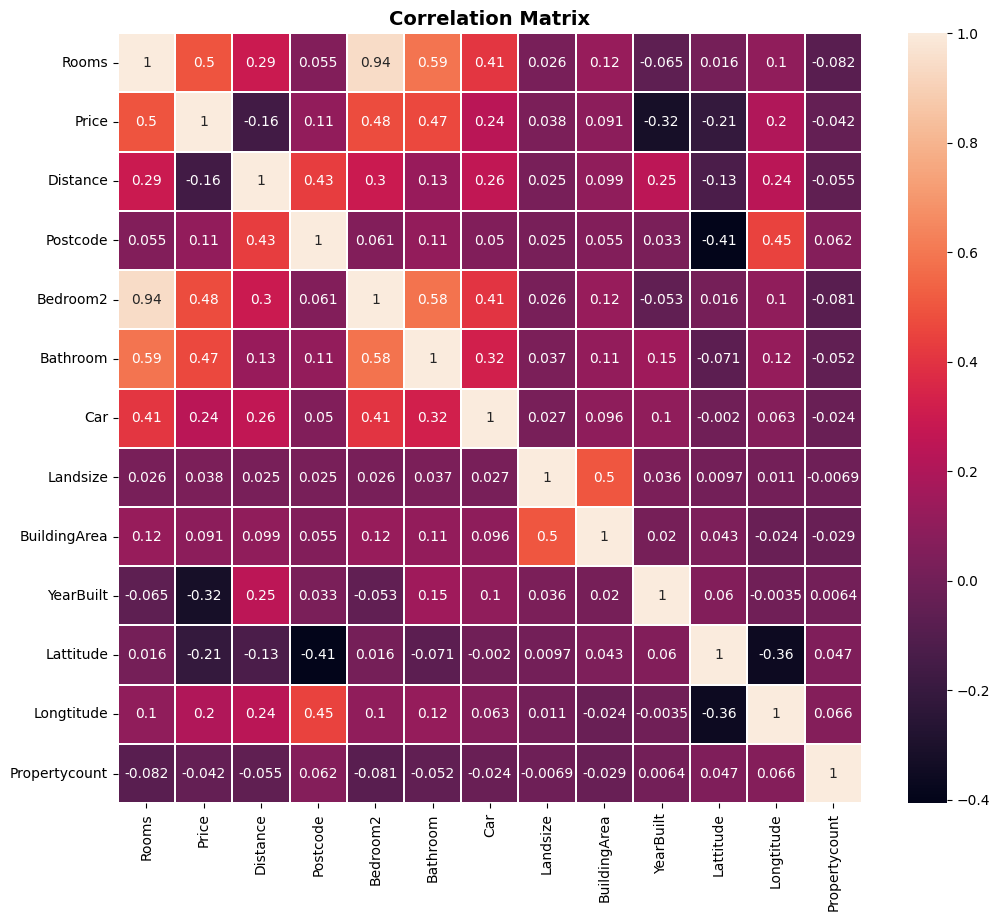

In [72]:
# handling missing value
plt.figure(figsize=(12,10))
sns.heatmap(df[num_col].corr(),
            linewidths=0.1,annot=True) 
plt.title("Correlation Matrix", fontsize=14, fontweight="bold")
plt.show()

In [73]:
missing= df.isnull().sum()
missing_percentage= (missing/len(df))*100
missing_table= pd.concat([missing,missing_percentage.round(2)],axis= 1)
missing_table= missing_table.rename(columns={0: "missing value", 1: "Percent of total values"})
print(missing_table.loc[missing_percentage>0])

              missing value  Percent of total values
Car                      62                    0.460
BuildingArea           6450                   47.500
YearBuilt              5375                   39.580
CouncilArea            1369                   10.080


In [74]:
# handling missing value of numeric coolumn 
knn = KNNImputer(n_neighbors=5)
df[num_col]=knn.fit_transform(df[num_col])

In [75]:
df.isnull().sum()

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                 0
Landsize            0
BuildingArea        0
YearBuilt           0
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
Month_sold          0
Year_sold           0
day_sold            0
dtype: int64

In [76]:
df["CouncilArea"]=df.groupby("Suburb")["CouncilArea"].transform(
    lambda x:x.fillna(x.mode()[0] 
                      if not x.mode().empty 
                      else df["CouncilArea"].mode()[0])
)

In [77]:
# outlier hanlding 
df.columns

Index(['Suburb', 'Address', 'Rooms', 'Type', 'Price', 'Method', 'SellerG', 'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude', 'Regionname', 'Propertycount', 'Month_sold', 'Year_sold', 'day_sold'], dtype='object')

In [78]:
def outlier_fill(df,var,method,low_quantile=0.25,high_quantile=0.75):
    if method =="IQR":
        q1 = df[var].quantile(low_quantile)
        q3 = df[var].quantile(high_quantile)
        IQR = q3 - q1
        min_range = q1 - (1.5 * IQR)
        max_range = q3 + (1.5 * IQR)
    elif method=="z_score":
        min_range = df[var].mean() - 3*df[var].std()
        max_range = df[var].mean() + 3*df[var].std()
    else:
        raise ValueError("Method should be 'IQR' or 'z_score'")
    return min_range, max_range


In [79]:
# check outlier 
def check_outlier(df,col_name,method):
    min_range,max_range= outlier_fill(df,col_name,method)
    outlier= (df[col_name]>max_range) | (df[col_name]<min_range)
    if outlier.any():
        return True , outlier.sum()
    else:
        return False, 0

In [80]:
# checking 
for col in num_col:
    print(col,check_outlier(df,col,"z_score"))

Rooms (True, np.int64(86))
Price (True, np.int64(232))
Distance (True, np.int64(246))
Postcode (True, np.int64(162))
Bedroom2 (True, np.int64(99))
Bathroom (True, np.int64(143))
Car (True, np.int64(138))
Landsize (True, np.int64(24))
BuildingArea (True, np.int64(8))
YearBuilt (True, np.int64(17))
Lattitude (True, np.int64(139))
Longtitude (True, np.int64(174))
Propertycount (True, np.int64(359))


In [81]:
# remove outlier 
def replace(df,var,method,plot=False):
    before = df[var].copy() 
    min_range,max_range= outlier_fill(df,var,method,0.25,0.75)
    df.loc[(df[var]<min_range),var]= min_range
    df.loc[df[var]>max_range,var]=max_range
    if plot: 
        fig, axes = plt.subplots(1, 2, figsize=(15,4))
        sns.histplot(before, ax=axes[0], kde=True)
        sns.histplot(df[var], ax=axes[1], kde=True)
        axes[0].set_title(f"{var} Before", fontsize=13)
        axes[1].set_title(f"{var} After", fontsize=13)
        plt.tight_layout()
        plt.show()

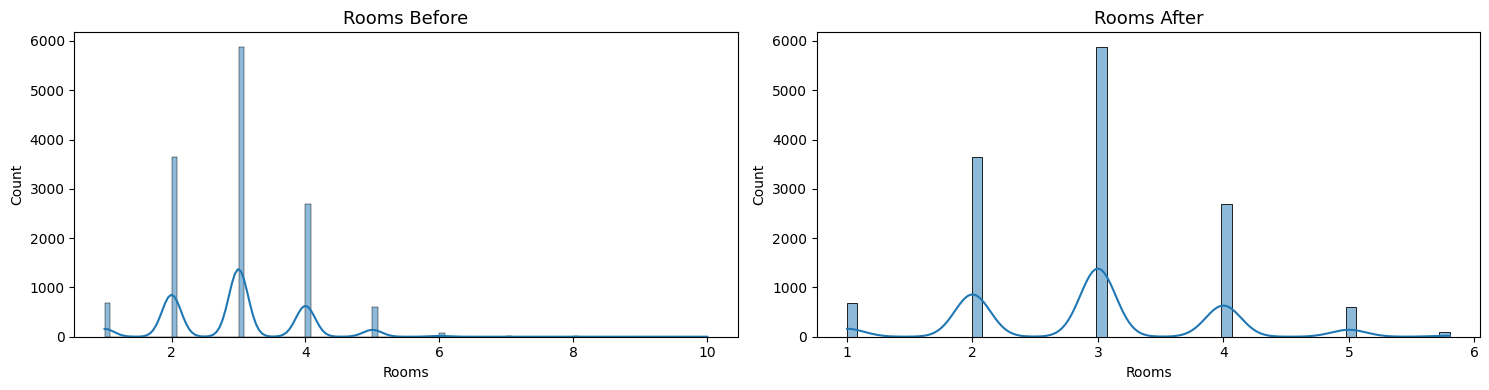

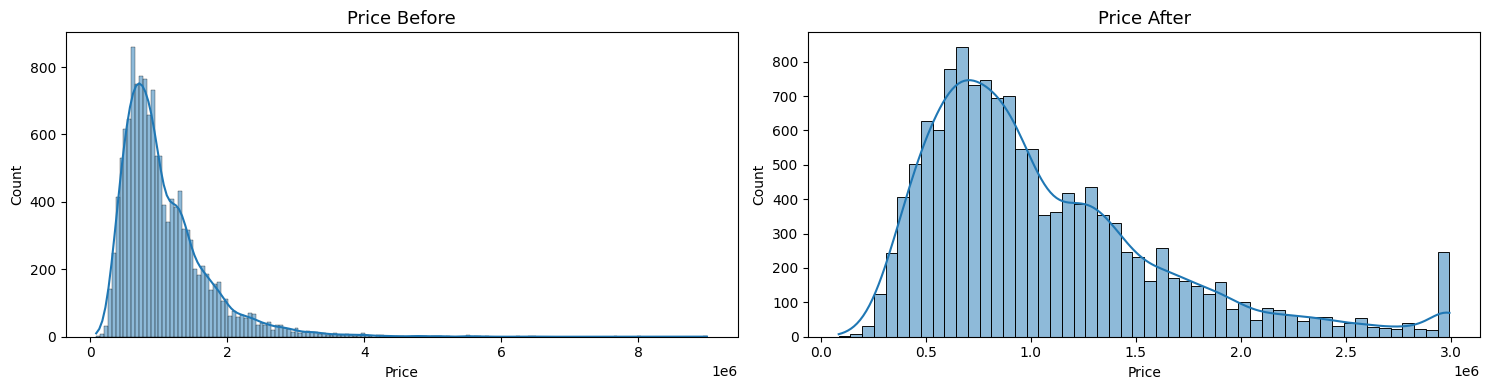

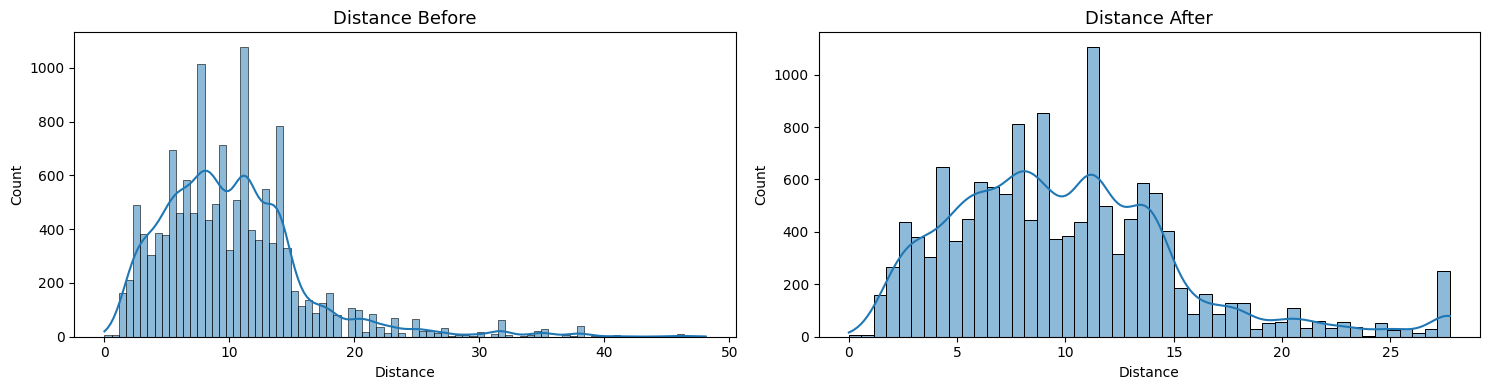

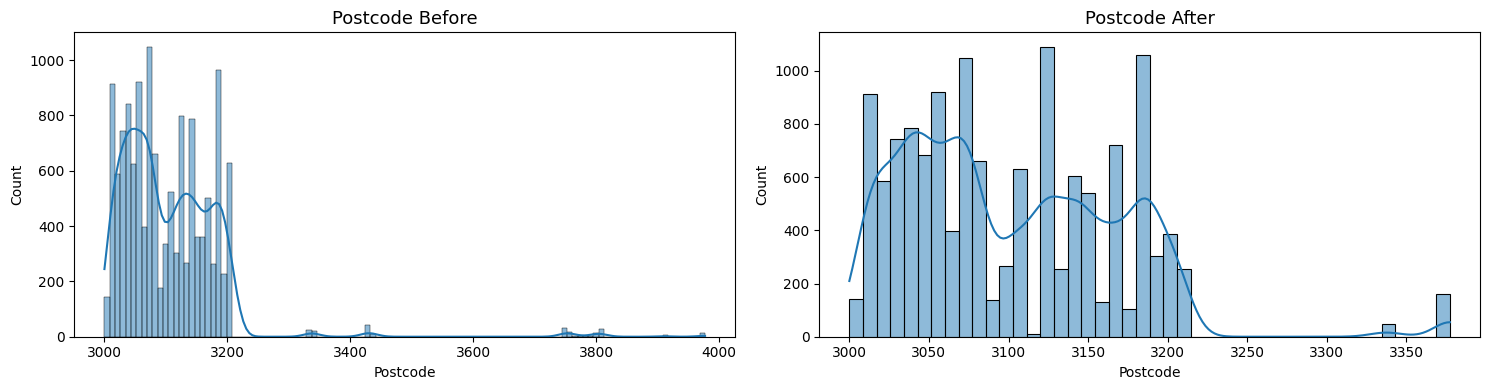

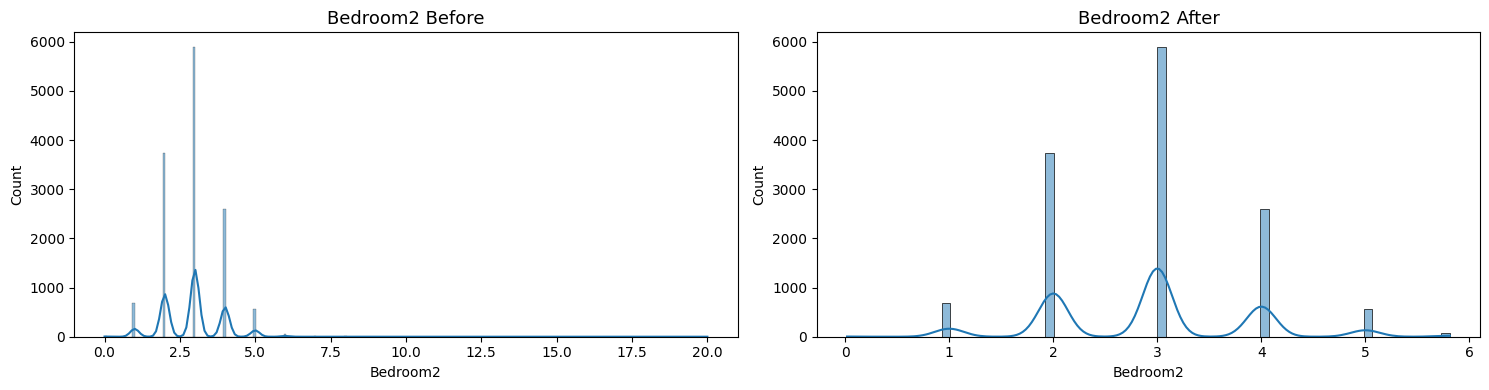

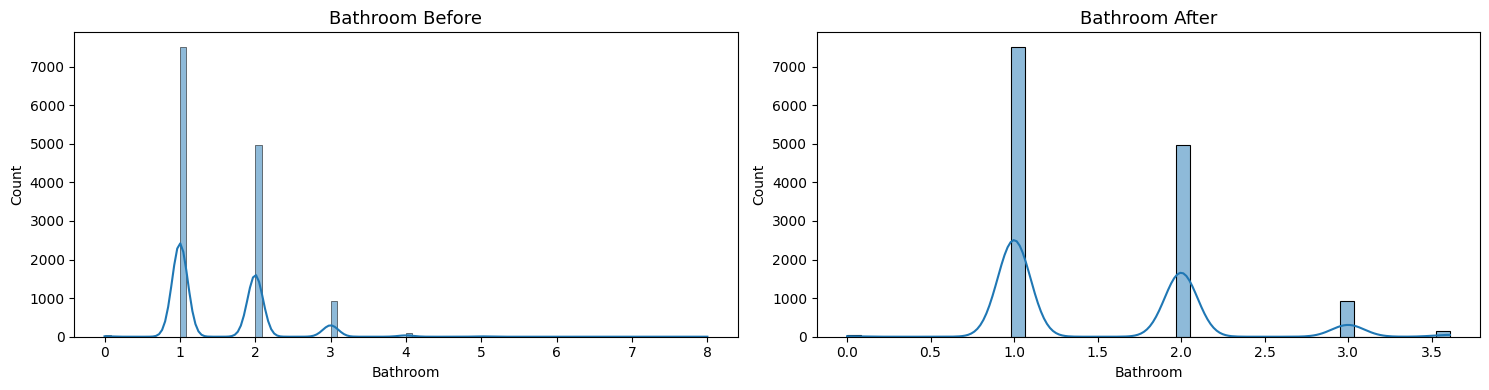

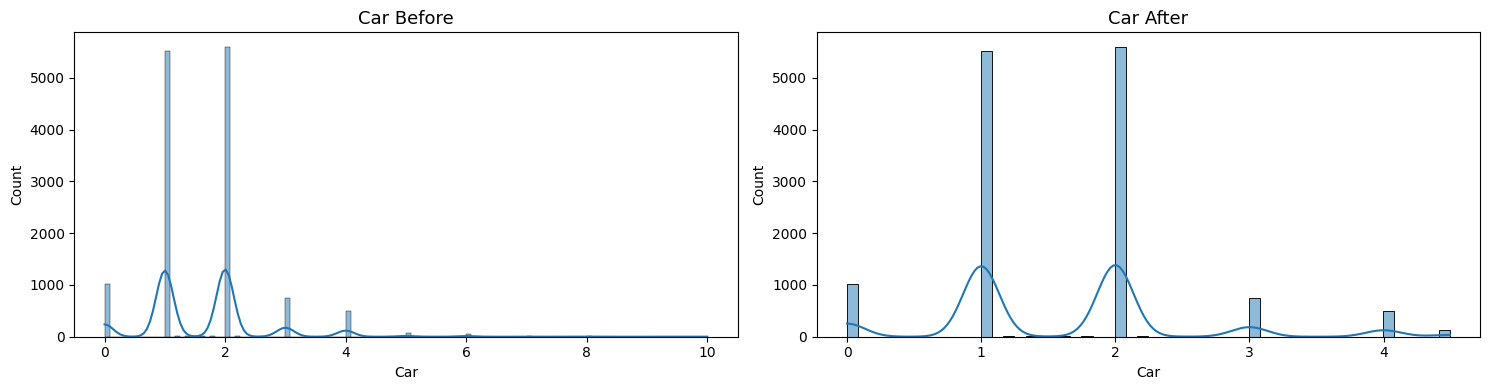

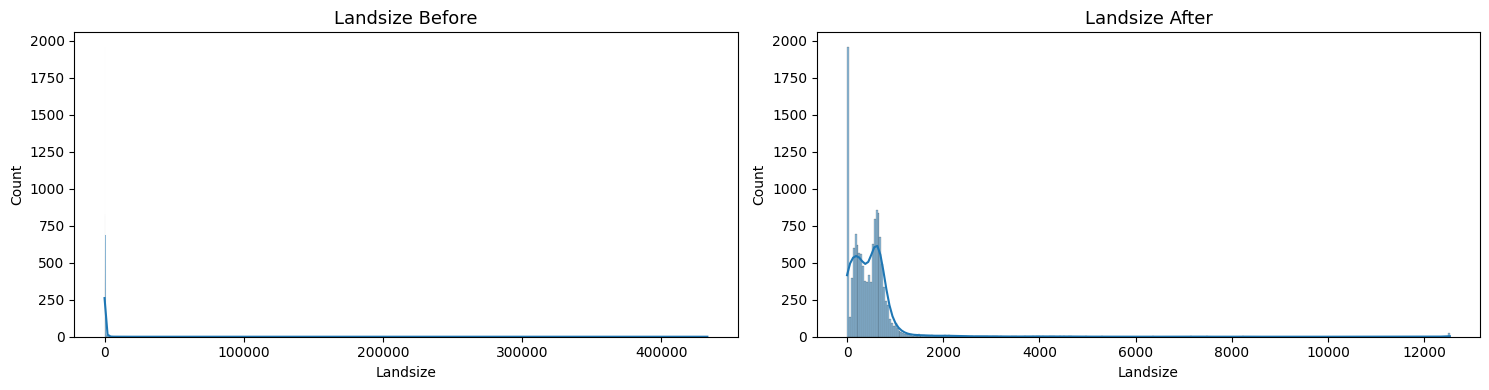

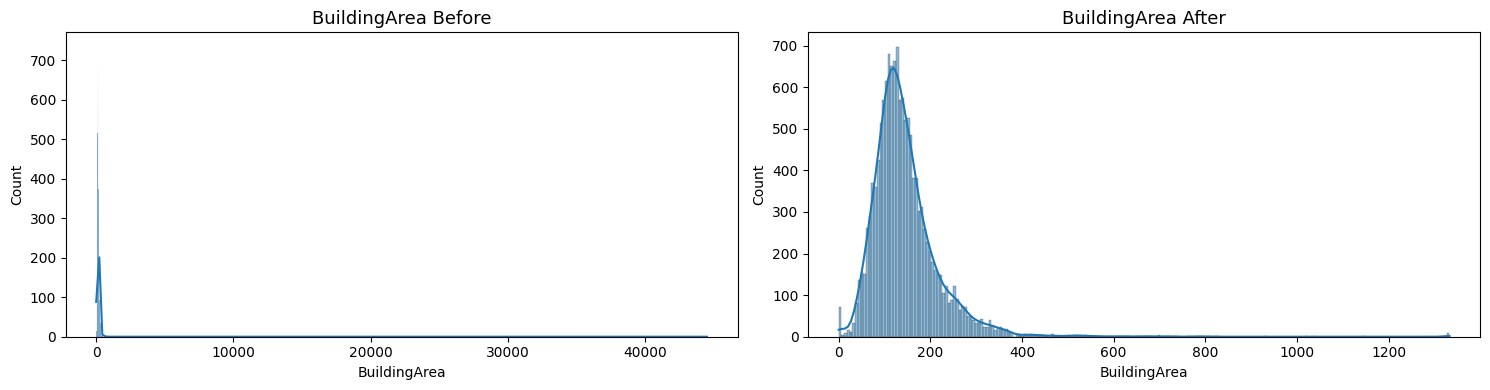

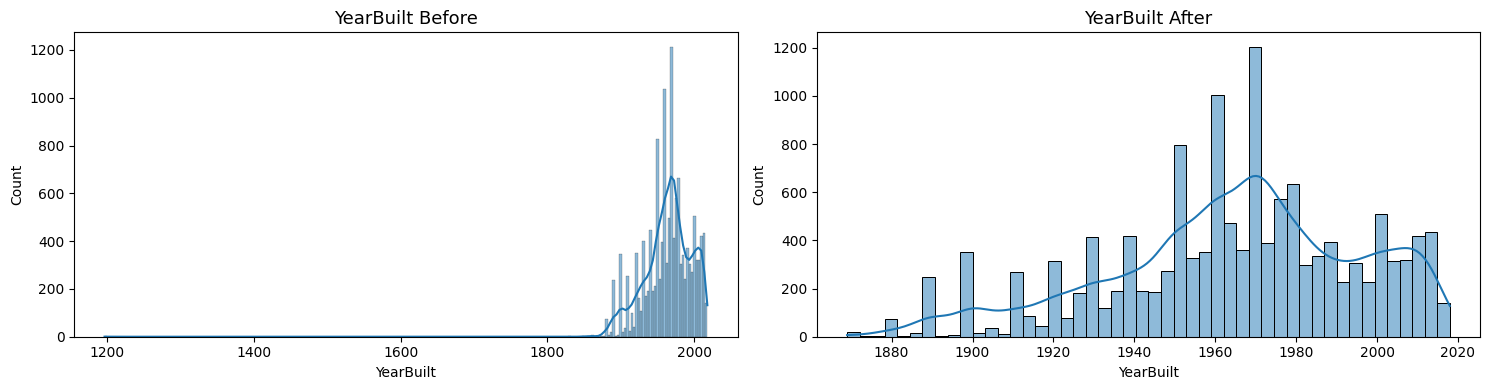

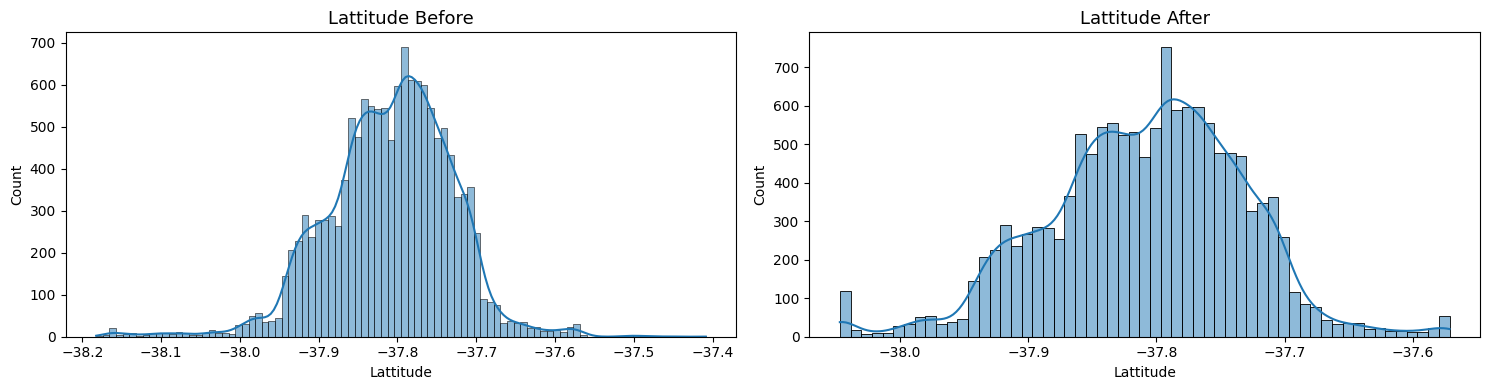

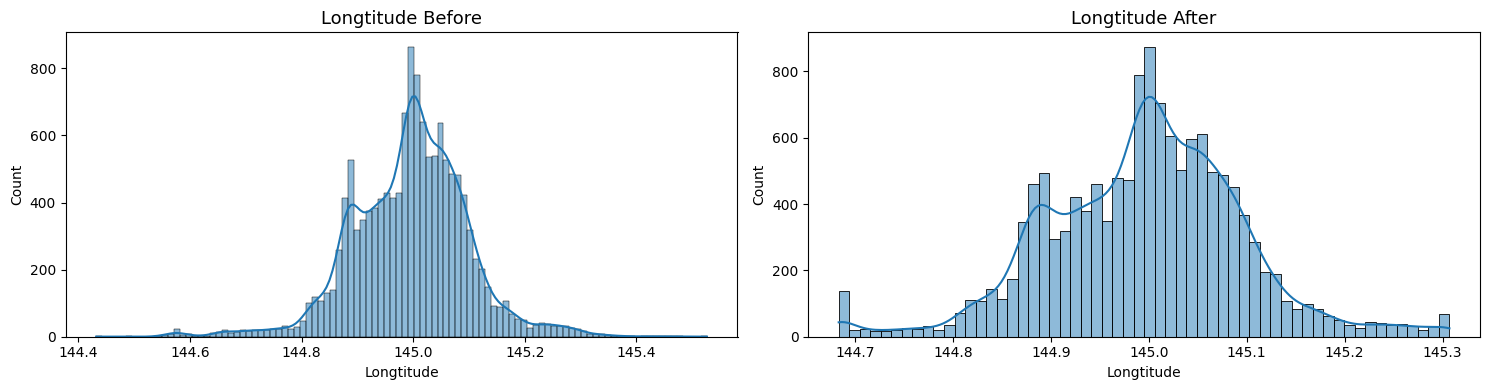

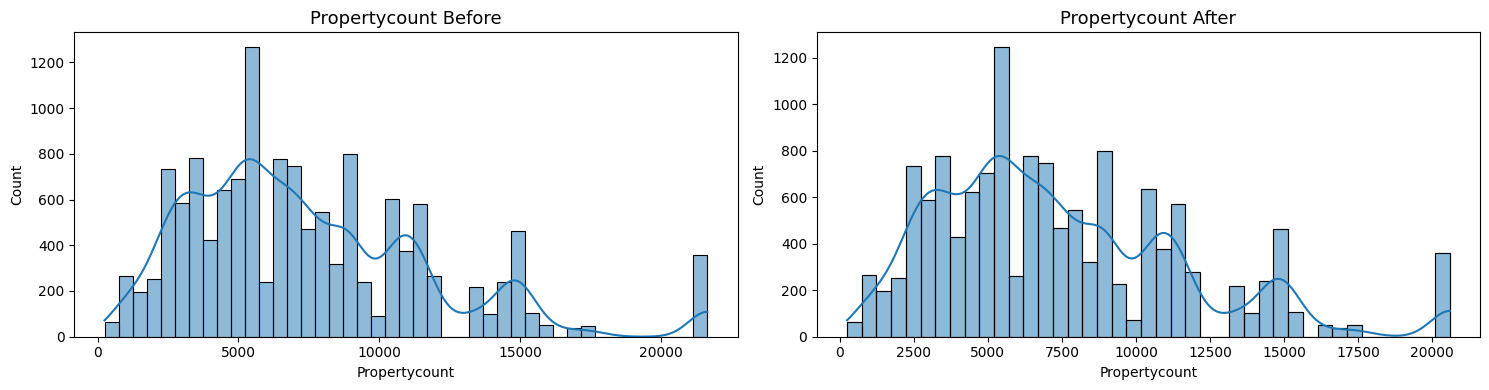

In [82]:
for col in num_col:
    replace(df,col,"z_score",True)

In [83]:
df.drop(["Address","Date","YearBuilt"],inplace=True,axis=1)
num_col.remove("YearBuilt")
obj_col.remove("Address")
obj_col.remove("Date")

In [84]:
obj_col

['Suburb',
 'Type',
 'Method',
 'SellerG',
 'CouncilArea',
 'Regionname',
 'day_sold']

In [85]:
for col in obj_col:
    le=LabelEncoder()
    df[col]=le.fit_transform(df[col])

In [86]:
# model building Model Building
""" After handling missing and outlier, extracting of new features and encoding all features, long story short, after Feature Engineering, it is time to build and train machine learning models.
This section contains:
Model Building for Baseline Score
Visual Comparing of Model Performances
Hyper-parameter Optimization
Feature Importance Visualization of Best Model
Feature Importance
Permutation Importance
Building and Saving Best Model
 """

' After handling missing and outlier, extracting of new features and encoding all features, long story short, after Feature Engineering, it is time to build and train machine learning models.\nThis section contains:\nModel Building for Baseline Score\nVisual Comparing of Model Performances\nHyper-parameter Optimization\nFeature Importance Visualization of Best Model\nFeature Importance\nPermutation Importance\nBuilding and Saving Best Model\n '

In [87]:
x=df.drop("Price",axis= 1)
y= df["Price"]

In [88]:
x_train, x_test, y_train,y_test= train_test_split(x,y,test_size= 0.2, random_state= 42)

In [89]:
# compare all the model after traning thme with the train data 
models={
    "Lasso": {"model":Lasso(max_iter=5000)},
    "LinearRegression": {"model": LinearRegression()},
    "Ridge":{"model":Ridge()},
    "ElasticNet":{"model":ElasticNet(max_iter=5000)},
    "KNeighborsRegressor":{"model":KNeighborsRegressor()},
    "RandomForestRegressor":{"model":RandomForestRegressor()},
    "GradientBoostingRegressor":{"model":GradientBoostingRegressor()},
    "AdaBoostRegressor":{"model": AdaBoostRegressor(n_estimators = 5, 
                                                           learning_rate = 1.2, 
                                                           loss = 'exponential', 
                                                           random_state = 2)},
    "DecisionTreeRegressor":{"model":DecisionTreeRegressor(max_depth=9,
                                                           min_samples_split=4,
                                                           random_state=1)},
    "XGBRegressor":{"model":XGBRegressor(random_state=17,eval_metric="rmse")},
    "LightGBM":{"model":LGBMRegressor(random_state=17, verbose=-1)},
    "CatBoostRegressor":{"model":CatBoostRegressor(verbose=False)}
}

In [90]:
df_score = pd.DataFrame(columns=["model", "MAE", "MSE", "RMSE", "R2"])
for name, regressor in models.items():
    print("running: ",name)
    regressor["model"].fit(x_train,y_train)
    y_pred = regressor["model"].predict(x_test)
    y_train_predict= regressor["model"].predict(x_train)
    
    mae_test= metrics.mean_absolute_error(y_test,y_pred)
    mse_test=metrics.mean_squared_error(y_test,y_pred)
    rmse_test=np.sqrt(metrics.mean_squared_error(y_test,y_pred))
    r2_test= metrics.r2_score(y_test,y_pred)
    
    mae_train= metrics.mean_absolute_error(y_train,y_train_predict)
    mse_train=metrics.mean_squared_error(y_train,y_train_predict)
    rmse_train=np.sqrt(metrics.mean_squared_error(y_train,y_train_predict))
    r2_train= metrics.r2_score(y_train,y_train_predict)
    
    print("\n".join([f"MAE test:   {mae_test}",
                     f"MSE test:   {mse_test}",
                     f"RMSE test:  {rmse_test}",
                     f"R2 test:    {r2_test}\n"])
          )
    print("\n".join([f"MAE train:  {mae_train}",
                     f"MSE train:  {mse_train}",
                     f"RMSE train: {rmse_train}",
                     f"R2 train:   {r2_train}\n"])
          )
    df_score.loc[len(df_score)] = [name, mae_test, mse_test, rmse_test, r2_test]
    

running:  Lasso
MAE test:   231347.61411982565
MSE test:   103641433125.77043
RMSE test:  321933.8955838146
R2 test:    0.6942164197398788

MAE train:  234221.20650529876
MSE train:  104597185581.72876
RMSE train: 323414.8815093838
R2 train:   0.6873599501920962

running:  LinearRegression
MAE test:   231347.8743394449
MSE test:   103641125580.40453
RMSE test:  321933.41793048533
R2 test:    0.6942173271214176

MAE train:  234222.10662467376
MSE train:  104597185216.33199
RMSE train: 323414.8809444797
R2 train:   0.6873599512842639

running:  Ridge
MAE test:   231330.65839661914
MSE test:   103649220534.44714
RMSE test:  321945.9900890942
R2 test:    0.694193443777136

MAE train:  234167.83801487548
MSE train:  104599347340.68481
RMSE train: 323418.2235754269
R2 train:   0.6873534887139605

running:  ElasticNet
MAE test:   245453.59858547975
MSE test:   119306420434.98021
RMSE test:  345407.61490589665
R2 test:    0.6479984569071314

MAE train:  247903.95816069754
MSE train:  121464673

In [91]:
df_score

,model,MAE,MSE,RMSE,R2
0,Lasso,231347.614,103641433125.770,321933.896,0.694
1,LinearRegression,231347.874,103641125580.405,321933.418,0.694
2,Ridge,231330.658,103649220534.447,321945.990,0.694
3,ElasticNet,245453.599,119306420434.980,345407.615,0.648
4,KNeighborsRegressor,219776.600,109023944092.528,330187.741,0.678
5,RandomForestRegressor,146908.233,49581264243.165,222668.508,0.854
6,GradientBoostingRegressor,163709.346,58820100668.257,242528.556,0.826
7,AdaBoostRegressor,262502.466,123066093342.271,350807.773,0.637
8,DecisionTreeRegressor,188166.109,80357067376.028,283473.222,0.763
9,XGBRegressor,144613.423,45981686805.502,214433.409,0.864


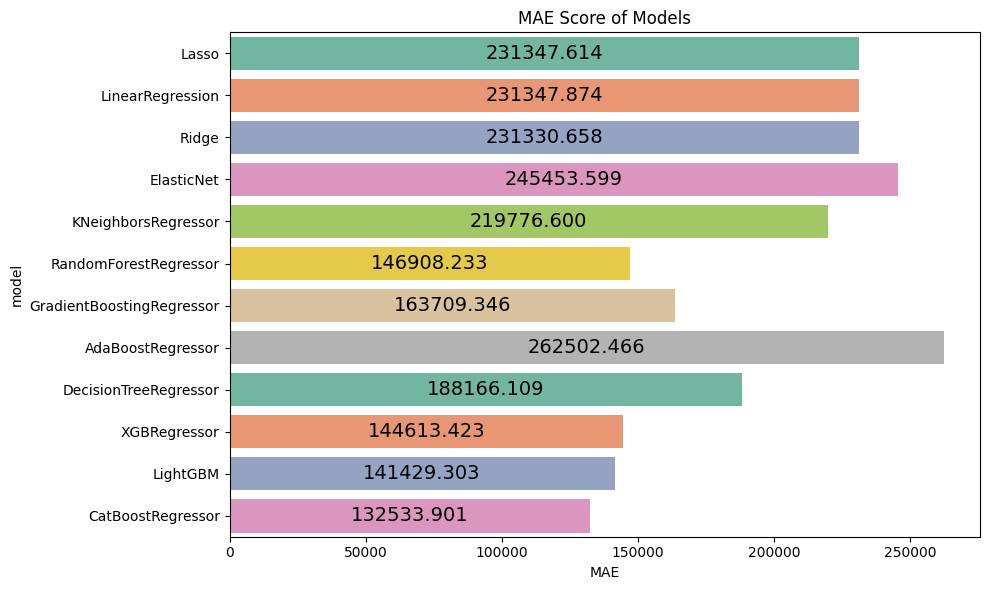

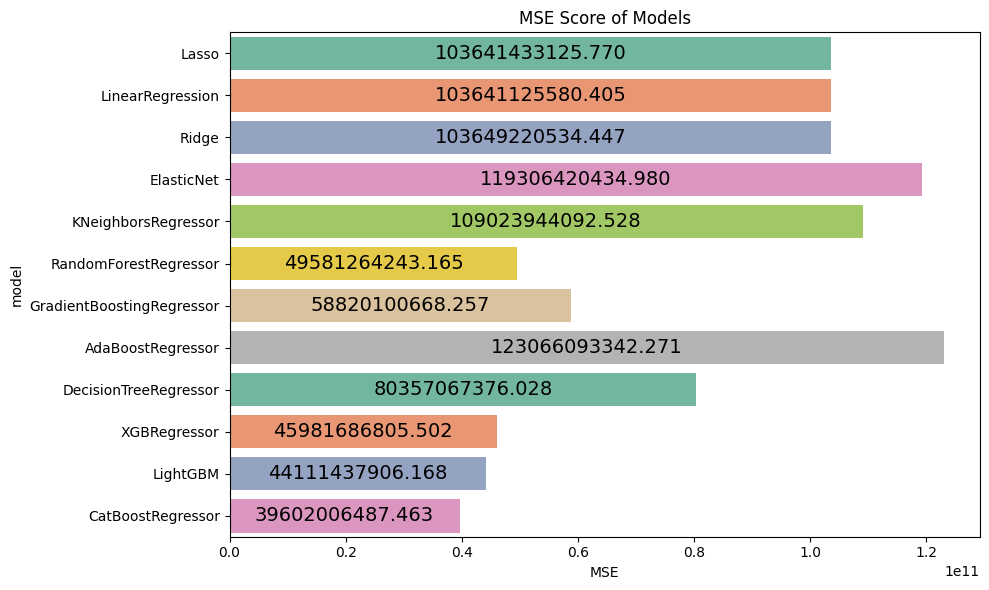

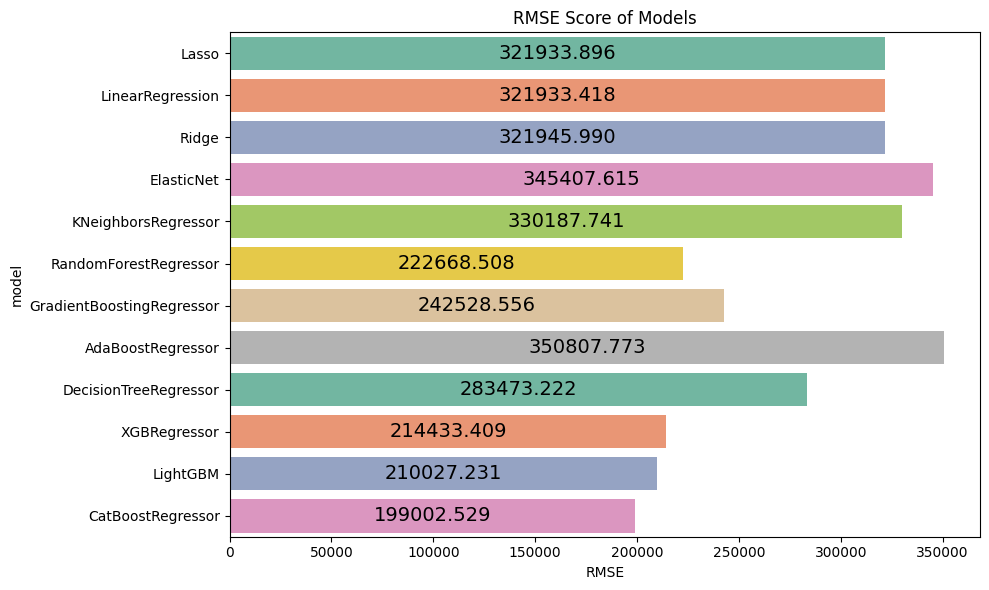

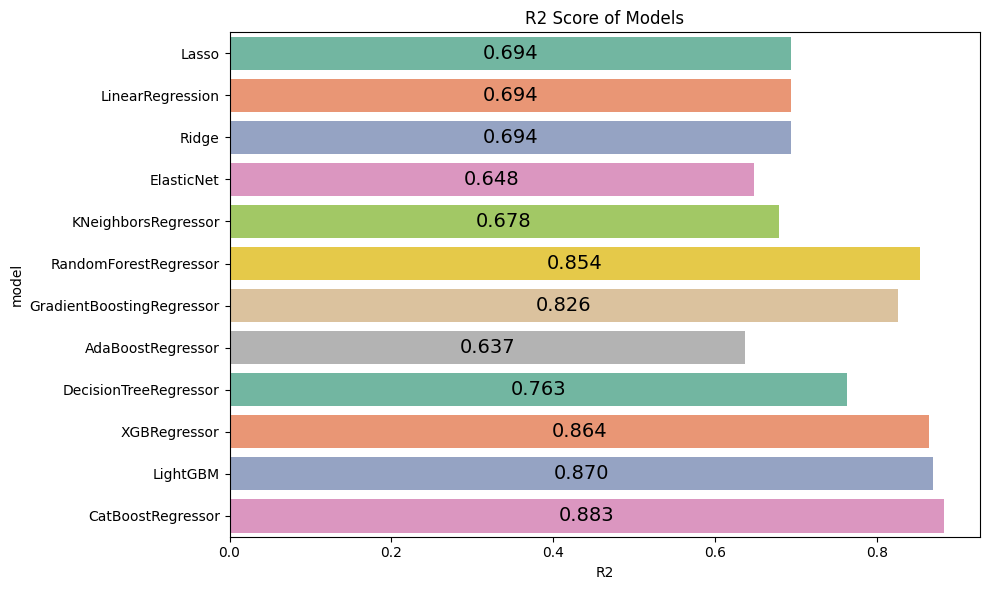

In [92]:
for col in df_score.columns[1::]:
    plt.figure(figsize=(10,6))
    ax=sns.barplot(data=df_score,x=col,y="model",palette="Set2")
    for c in ax.containers:
        ax.bar_label(c,fmt="{:1.3f}",fontsize=14,label_type="center")
    plt.title(f"{col} Score of Models")
    plt.tight_layout()
    plt.show()

In [93]:
""" #Hyper Parameter Optimization
#Four model have been chosen for hyperparameter tuning. These are:
LGBM
XGB
CatBoost
Random Forest
After (shallow) hyperparameter tuning with GridSearchCv (may give better results with Optuna), CatBoost has better result than others. """

' #Hyper Parameter Optimization\n#Four model have been chosen for hyperparameter tuning. These are:\nLGBM\nXGB\nCatBoost\nRandom Forest\nAfter (shallow) hyperparameter tuning with GridSearchCv (may give better results with Optuna), CatBoost has better result than others. '

In [94]:
def base_model(x,y,scoring="r2"):
    models=[("Lasso",Lasso(max_iter=5000)),
           ("LinearRegression",LinearRegression()),
           ("Ridge",Ridge()),
           ("ElasticNet",ElasticNet(max_iter=5000)),
           ("KNeighborsRegressor",KNeighborsRegressor()),
           ("RandomForestRegressor",RandomForestRegressor()),
           ("GradientBoostingRegressor",GradientBoostingRegressor()),
           ("AdaBoostRegressor",AdaBoostRegressor(n_estimators = 5, 
                                                learning_rate = 1.2, 
                                                loss = 'exponential', 
                                                random_state = 2)),
           ("DecisionTreeRegressor",DecisionTreeRegressor(max_depth=9,
                                                           min_samples_split=4,
                                                           random_state=1)),
           ("XGB",XGBRegressor(random_state=17,eval_metric="rmse")),
           ("LightGBM",LGBMRegressor(random_state=17, verbose=-1)),
           ("CatBoostRegressor",CatBoostRegressor(verbose=False))]
    for name, regressor in models:
        cv_result= cross_validate(regressor,x,y,cv=5,scoring=scoring)
        print(f"R2:{round(cv_result['test_score'].mean(),4)} ({name})")

In [95]:
LGM_params={"n_estimators":[100,300,500],
            "learning_rate":[0.01,0.1,0.2],
            "max_depth":[5,7,9]}
XGB_Regressor_prams={"n_estimators":[100,300,500],
            "learning_rate":[0.01,0.1,0.2],
            "max_depth":[5,7,9]}
Cat_Boost_params={"iterations": [100, 500, 1000],
                   "learning_rate": [0.01, 0.1, 0.2],
                   "depth": [5, 7, 9]}
Random_Forest_params={"n_estimators":[100,200,300],
                      "max_depth":[3,4,5,None]}

In [96]:
models=[("LightGBM",LGBMRegressor(random_state=17, verbose=-1),LGM_params),
        ("XGB",XGBRegressor(),XGB_Regressor_prams),
        ("CatBoost",CatBoostRegressor(verbose=False),Cat_Boost_params),
        ("RandomForestRegressor",RandomForestRegressor(),Random_Forest_params)]

In [97]:
def hyperparameter_optimization(x,y,cv=5,scoring="r2"):
    print("hyperparameter optimization.....")
    best_model={}
    for name, regressor,params in models:
        print(f"........{name}....")
        cv_results = cross_validate(regressor, x, y, cv=cv, scoring=scoring)
        print(f"{scoring}(Before): {round(cv_results['test_score'].mean(),4)}")
        
        gs_best=GridSearchCV(regressor,params,cv=cv,n_jobs=-1,verbose=False)
        gs_best.fit(x,y)
        
        final_model = gs_best.best_estimator_
        
        cv_results_after=cross_validate(final_model,x,y,cv=cv,scoring=scoring)
        print(f"{scoring}(After): {round(cv_results_after['test_score'].mean(),4)}")
        print(f"{name} best params: {gs_best.best_params_}\n")
        best_model[name]=final_model
    return best_model

In [98]:
def fit_model(x,y):
    base_model(x,y)
    best_models=hyperparameter_optimization(x,y)
    return best_models

best_models =fit_model(x_train,y_train)

R2:0.6837 (Lasso)
R2:0.6837 (LinearRegression)
R2:0.6837 (Ridge)
R2:0.6322 (ElasticNet)
R2:0.6565 (KNeighborsRegressor)
R2:0.8443 (RandomForestRegressor)
R2:0.8264 (GradientBoostingRegressor)
R2:0.6491 (AdaBoostRegressor)
R2:0.7447 (DecisionTreeRegressor)
R2:0.8547 (XGB)
R2:0.8641 (LightGBM)
R2:0.8726 (CatBoostRegressor)
hyperparameter optimization.....
........LightGBM....
r2(Before): 0.8641
r2(After): 0.8693
LightGBM best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 500}

........XGB....
r2(Before): 0.8547
r2(After): 0.869
XGB best params: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500}

........CatBoost....
r2(Before): 0.8726
r2(After): 0.8731
CatBoost best params: {'depth': 7, 'iterations': 1000, 'learning_rate': 0.1}

........RandomForestRegressor....
r2(Before): 0.8439
r2(After): 0.8452
RandomForestRegressor best params: {'max_depth': None, 'n_estimators': 200}



In [99]:
final_model= best_models["CatBoost"].fit(x_train,y_train)

In [100]:
permutation= PermutationImportance(final_model,random_state=42,n_iter=10).fit(x_test,y_test)
display(eli5.show_weights(permutation, feature_names=x_test.columns.tolist()))

Weight,Feature
0.1924 ± 0.0121,Distance
0.1599 ± 0.0146,Lattitude
0.1237 ± 0.0118,Type
0.1131 ± 0.0069,Landsize
0.0994 ± 0.0100,Longtitude
0.0977 ± 0.0053,BuildingArea
0.0555 ± 0.0052,Rooms
0.0484 ± 0.0041,Postcode
0.0305 ± 0.0036,Bathroom
0.0130 ± 0.0027,CouncilArea


In [101]:
def plot_importance(model, type, features=None, x_test=None, y_test=None, save=False):
    if type == 'feature_importance':
        df_imp = pd.DataFrame({'Value': model.feature_importances_, 
                               'Feature': features.columns})
        
        plt.figure(figsize=(15, 6))
        sns.set_theme(font_scale=1)
        ax = sns.barplot(x="Feature", y="Value", 
                         data=df_imp.sort_values(by="Value", ascending=False),
                         palette='Set3')

        for container in ax.containers:
            ax.bar_label(container,  fmt="{:1.2f}", fontsize=12)
        plt.title('Feature Importance')
        plt.xticks(rotation=30)
        plt.tight_layout()
        if save:
            plt.savefig("feature_importance.png")
        plt.show()
        
    elif type == 'permutation_importance' and features is None:
        model_copy = model
        perm = PermutationImportance(model, random_state=42, n_iter=10).fit(x_test, y_test)
        df_imp = pd.DataFrame({'Feature': x_test.columns.tolist(),
                               'Value': perm.feature_importances_, 
                               'Std': perm.feature_importances_std_,})
        
        plt.figure(figsize=(15, 6))
        sns.set_theme(font_scale=1)
        ax = sns.barplot(x="Feature", y="Value", 
                         data=df_imp.sort_values(by="Value", ascending=False),
                         palette='Set3')

        for container in ax.containers:
            ax.bar_label(container,  fmt="{:1.4f}", fontsize=11)
        plt.title('Permutation Importance (test set)')
        plt.xticks(rotation=30)
        plt.tight_layout()
        if save:
            plt.savefig("permutation_importance.png")
        plt.show()
        
    else:
        return f'Unsupported importance type.'

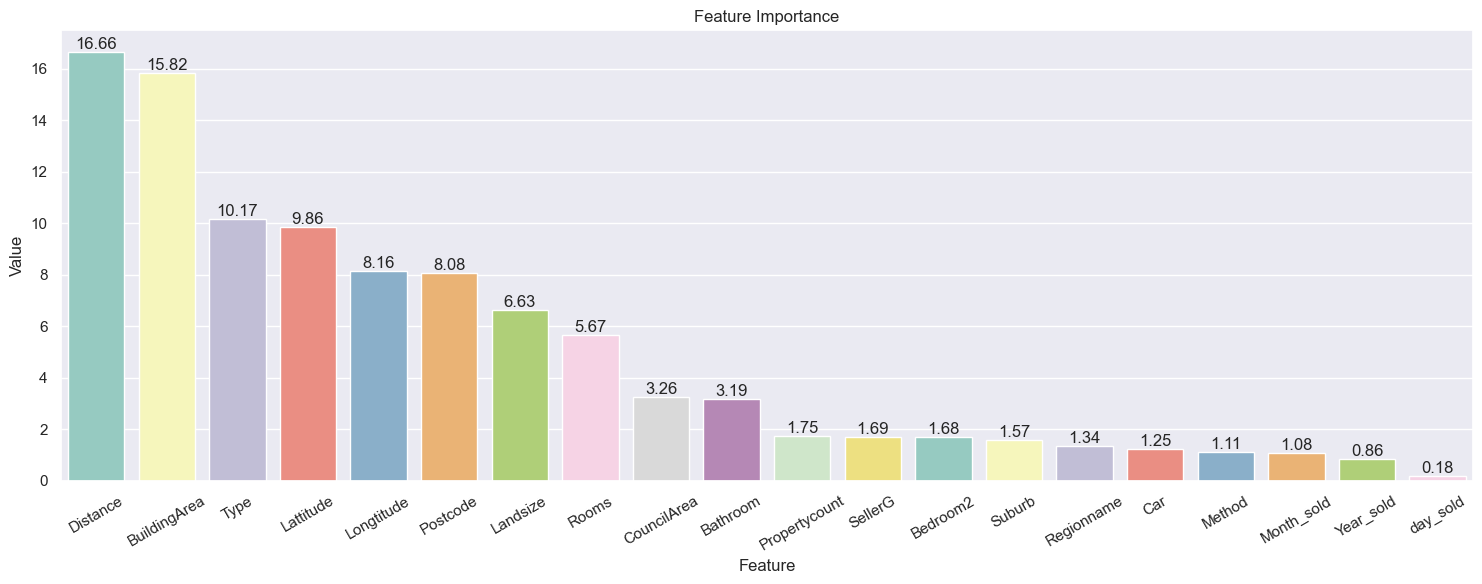

In [102]:
plot_importance(final_model, 'feature_importance', x)

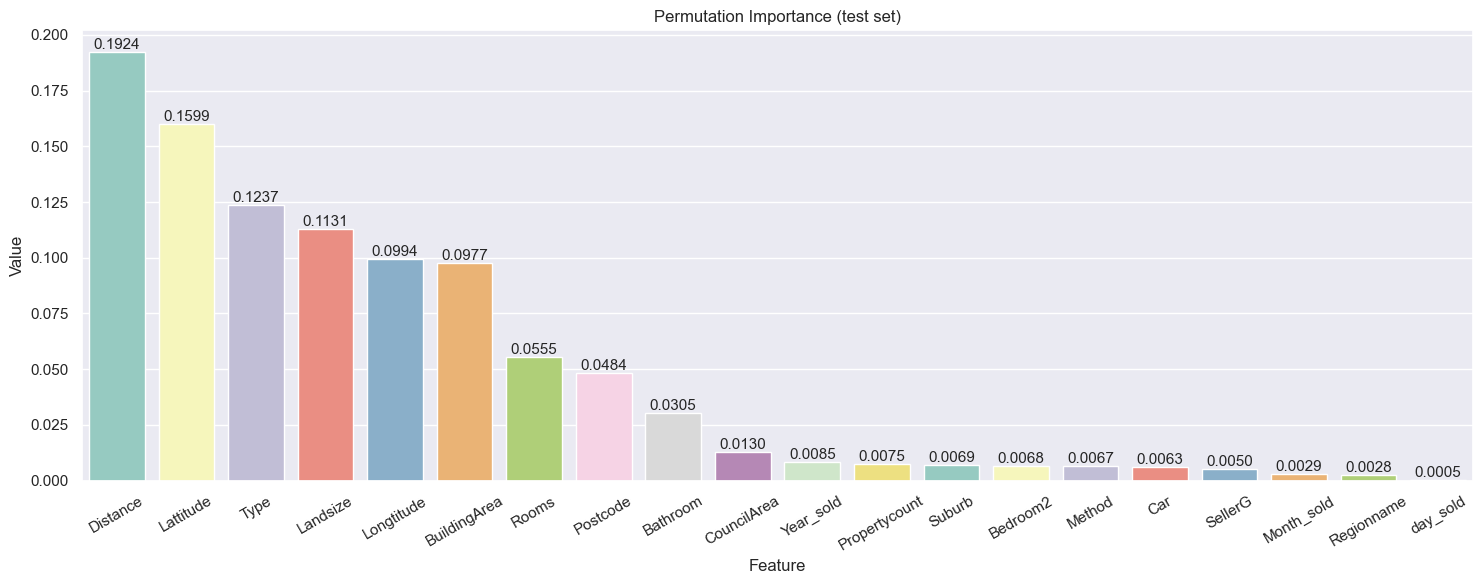

In [103]:
plot_importance(final_model, type='permutation_importance', x_test=x_test, y_test=y_test)

In [104]:
scores_r2 = cross_val_score(final_model, x, y, cv=5, scoring='r2')
print(f"R2  : {np.mean(scores_r2):.4f} (+/- {np.std(scores_r2):.4f})")

scores_mae = -cross_val_score(final_model, x, y, cv=5, scoring='neg_mean_absolute_error')
print(f"MAE : {np.mean(scores_mae):.4f} (+/- {np.std(scores_mae):.4f})")

scores_mse = -cross_val_score(final_model, x, y, cv=5, scoring='neg_mean_squared_error')
print(f"MSE : {np.mean(scores_mse):.4f} (+/- {np.std(scores_mse):.4f})")

scores_rmse = np.sqrt(scores_mse)
print(f"RMSE: {np.mean(scores_rmse):.4f} (+/- {np.std(scores_rmse):.4f})")

R2  : 0.8708 (+/- 0.0064)
MAE : 138890.7019 (+/- 10909.6850)
MSE : 43034079122.6543 (+/- 5520104098.6925)
RMSE: 207040.7625 (+/- 12969.2630)


In [ ]:
final_model.fit(x, y)
joblib.dump(final_model, 'final_model_catboost.pkl')

['final_model_catboost.pkl']

In [106]:
from sklearn.feature_selection import SelectFromModel
sel = SelectFromModel(final_model, threshold=0.01, prefit=True)
X_trans = sel.transform(x)

In [107]:
final_model.fit(X_trans, y)
scores_r2 = cross_val_score(final_model, X_trans, y, cv=5, scoring='r2')
print(f"R2  : {np.mean(scores_r2):.4f} (+/- {np.std(scores_r2):.4f})")

scores_mae = -cross_val_score(final_model, X_trans, y, cv=5, scoring='neg_mean_absolute_error')
print(f"MAE : {np.mean(scores_mae):.4f} (+/- {np.std(scores_mae):.4f})")

scores_mse = -cross_val_score(final_model, X_trans, y, cv=5, scoring='neg_mean_squared_error')
print(f"MSE : {np.mean(scores_mse):.4f} (+/- {np.std(scores_mse):.4f})")

scores_rmse = np.sqrt(scores_mse)
print(f"RMSE: {np.mean(scores_rmse):.4f} (+/- {np.std(scores_rmse):.4f})")


R2  : 0.8708 (+/- 0.0064)
MAE : 138890.7019 (+/- 10909.6850)
MSE : 43034079122.6543 (+/- 5520104098.6925)
RMSE: 207040.7625 (+/- 12969.2630)


In [108]:
# Final R2 score ko % me print karna
final_r2 = np.mean(cross_val_score(final_model, x, y, cv=5, scoring='r2'))
print(f"Final Model Accuracy: {final_r2*100:.2f}%")


Final Model Accuracy: 87.08%
